# ASD vs TD classification: joint fusion of structural and functional MRI features (PyTorch)

In this notebook we build a joint-fusion neural network that discriminates subjects with Autism Spectrum Disorder (ASD) from typically developing controls (TD), by combining two complementary views of the brain extracted from MRI:

* Structural features (sMRI), i.e., descriptors of brain anatomy,
* Functional features (fMRI), i.e., descriptors of brain activity and functional connectivity.

We used resting-state fMRI (rs-fMRI) and T1-weighted structural MRI (T1w-MRI) data from the Autism Brain Imaging Data Exchange (ABIDE) I and II datasets, which aggregate neuroimaging data collected across multiple sites. The analysed cohort comprised $1383$ male participants from $35$ acquisition sites, classified as ASD (class 1) or TD (class 0). Functional time series were extracted from rs-fMRI using the Harvard--Oxford atlas. Eight regions of interest (ROIs) were excluded because their time series contained only zero values for most participants. Functional connectivity (FC) was then computed for each participant using pairwise Pearson correlation between regional time series. Only the upper triangular elements of each FC matrix were retained and flattened into a one-dimensional feature vector, for a total of $5253$ features. Structural morphological features were derived from T1w-MRI using FreeSurfer and the Desikan--Killiany atlas, yielding $221$ structural features per participant.

**What we will do in this notebook**

1. Load the structural and functional tables, merge them and scale the features (Sections 1-2)
2. Define the PyTorch model: one encoder per modality, and finally a fusion head (Section 3)
3. Build the training routine and select hyperparameters with *Optuna* (Section 4)
4. Evaluate with a stratified 10-fold cross-validation: first the two single-modality baselines (Section 5), then the joint-fusion model (Section 6)
5. Use *SHAP* to get explainability data to be analyzed in the next notebooks


## 1. Data loading and normalization

Structural and functional features are stored in two separate CSV files, ready to be used as model input. ABIDE is a multi-site dataset: scans were acquired with different scanners and protocols, which introduces site-related variability unrelated to the diagnosis. For this reason the features were harmonized across sites beforehand. The harmonization is already applied in the CSV files and is not repeated here.

We have already taken care of harmonization! It was performed using the Python package NeuroHarmonize as in [Saponaro et al., 2024](https://doi.org/10.1186/s40708-023-00217-4). In short, we estimated the NeuroHarmonize model parameters on the entire cohort of control subjects, by specifying the age as a covariate, whose effect is to be preserved during the harmonization process. Finally, we applied the estimated model on the entire sample of subjects with ASD and TD controls.

This section has three steps: loading the files (1.1), merging them into a single table (1.2) and scaling the features (1.3).

In [1]:
# silence library warnings to keep the notebook output readable
import logging, os
logging.disable(logging.WARNING)
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

### 1.1 Loading the CSV files

Both files contain one row per scan, identified by the `FILE_ID` column. Besides the features, each table carries some metadata columns (`SITE`, `Database_Abide`, `AGE_AT_SCAN`) and the diagnostic label `DX_GROUP`.

The files are read from `path_to_data`. The `data` folder in this path is used later to save the results (metrics, ROC curves and SHAP values), so make sure it exists and is writable.

In [2]:
import pandas as pd
import numpy as np

path_to_data='/envs/data/jfpp/'
path_to_output_data='./data/'
DF_struct = pd.read_csv(os.path.join(path_to_data,'Harmonized_structural_features.csv'))
DF_funct  = pd.read_csv(os.path.join(path_to_data,'Harmonized_functional_features.csv'))

### 1.2 Merging the two modalities

The two tables are combined, so that each subject has both structural and functional features in the same DataFrame:

1. `FILE_ID` becomes the index of both tables, and they are joined with an *inner join*: only subjects with both modalities are kept
2. The metadata columns that already appear in the structural table are dropped from the functional one, to avoid duplicated columns after the join
3. The label is recoded: `DX_GROUP == -1` becomes `0`, so that the target is binary in `{0, 1}`, as required by the binary cross-entropy loss used later
4. The remaining metadata columns (`SITE`, `Database_Abide`, `AGE_AT_SCAN`, `FILE_ID`) are removed, so that the classifier only sees imaging features

The resulting table, `DF_normalized`, has a fixed column layout on which all the following cells rely:

| Columns | Content |
|---|---|
| `0` | `DX_GROUP` |
| `1` to `221` | structural features |
| `222` onwards | functional features |

The last line of the cell displays the table, so you can check its shape.

In [3]:
DF_struct = DF_struct.set_index('FILE_ID')
DF_funct = DF_funct.set_index('FILE_ID')
DF_funct= DF_funct.drop(['SITE', 'Database_Abide', 'AGE_AT_SCAN', 'DX_GROUP'], axis =1)
DF_merge = DF_struct.join(DF_funct,how='inner')
DF_merge = DF_merge.reset_index()
DF_merge.loc[DF_merge.DX_GROUP == -1, 'DX_GROUP'] = 0
DF_data = DF_merge.drop(['SITE', 'Database_Abide', 'AGE_AT_SCAN', 'FILE_ID'], axis =1)
DF_data

,DX_GROUP,lh_caudalanteriorcingulate_GrayVol,lh_caudalanteriorcingulate_ThickAvg,lh_caudalanteriorcingulate_ThickStd,lh_caudalmiddlefrontal_GrayVol,lh_caudalmiddlefrontal_ThickAvg,lh_caudalmiddlefrontal_ThickStd,lh_cuneus_GrayVol,lh_cuneus_ThickAvg,lh_cuneus_ThickStd,...,5243,5244,5245,5246,5247,5248,5249,5250,5251,5252
0,1,4688.148643,2.930110,0.587509,8800.363280,2.325779,0.668543,3869.253795,1.951518,0.540253,...,-2.705760,-4.941687,-0.313784,-1.580897,-0.578138,0.800900,1.147299,-0.890745,4.318482,1.020236
1,1,3984.677523,2.882359,0.460643,6547.377947,2.435749,0.586677,3314.786185,2.122949,0.471802,...,-1.542383,-2.030129,0.686534,-3.049052,1.500650,-0.057321,-0.400296,0.395253,3.167437,-0.097813
2,1,4784.864858,2.737028,0.637104,9181.350601,2.683773,0.684515,4604.428639,2.103867,0.601115,...,3.010815,1.032087,-0.068159,-3.309840,-0.691436,-0.463286,-1.549897,0.358268,1.696029,-1.191784
3,1,2139.453979,2.286036,0.518532,6268.548302,2.528375,0.634880,3458.444707,1.957845,0.452045,...,2.469967,2.228592,-1.300355,1.016235,0.685534,-1.513635,0.778284,1.085581,-2.308573,-2.923374
4,1,6194.078262,2.955411,0.831313,11308.319412,2.380809,0.625219,4595.339126,2.124974,0.562617,...,1.399667,-1.951666,-1.588347,-0.684389,-1.423833,0.770992,-2.364999,3.107560,1.168626,-0.658174
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1378,0,2760.894710,2.719528,0.645727,8044.910494,2.797142,0.640982,4603.816833,2.117092,0.538822,...,-2.494394,-2.287528,-2.692700,0.572010,-2.051990,-2.813308,-2.631377,-0.497931,5.814645,-1.464597
1379,0,3978.719928,2.766787,0.606700,7192.725506,2.764371,0.534917,5327.308393,2.102368,0.550826,...,-1.049086,-0.655575,2.143340,-4.697099,-0.670624,0.330856,-0.364826,2.593785,3.250819,1.271162
1380,0,2954.162825,2.897091,0.770469,8104.601082,2.905285,0.594737,5416.908509,2.291841,0.581176,...,0.638060,3.033216,-0.703276,0.765123,-0.741325,-0.049255,1.498713,-0.294101,9.475724,-0.006066
1381,0,3276.342103,2.925723,0.678409,7901.169064,2.882859,0.576567,5325.562172,2.209474,0.475749,...,-2.245569,1.083005,-0.479682,-0.084593,2.388419,-1.887193,2.116627,-2.294673,5.933953,0.806741


### 1.3 Feature arrays

From the table we extract two numpy arrays: `X_all` with the features and `y_all` with the labels. The features are **not scaled here**: the scaler is fitted inside every cross-validation fold, on the training subjects only (Section 4.1), so that no information about the test subjects enters the preprocessing.

Column layout of `X_all`: columns `0..220` are the structural features, columns `221..5473` the functional ones.

In [4]:
N_STRUCT, N_FUNC = 221, 5253

X_all = DF_data.iloc[:, 1:].to_numpy(dtype=np.float64)    # features, UNSCALED (structural first, then functional)
y_all = DF_data.iloc[:, 0].to_numpy().astype(np.float32)  # labels in {0, 1}

assert X_all.shape[1] == N_STRUCT + N_FUNC, X_all.shape
assert set(np.unique(y_all)) == {0.0, 1.0}

print('subjects:', len(y_all), '| ASD:', int(y_all.sum()), '| TD:', int((1 - y_all).sum()))
print('X_all:', X_all.shape, '| structural', N_STRUCT, '| functional', N_FUNC)

subjects: 1383 | ASD: 680 | TD: 703
X_all: (1383, 5474) | structural 221 | functional 5253


## 2. PyTorch

We now import PyTorch and select the device: the GPU (`cuda`) if one is available, the CPU otherwise. Models and tensors are moved to `DEVICE` with `.to(DEVICE)` in the training code.

In [5]:
import torch
import torch.nn as nn

print('torch', torch.__version__)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', DEVICE)


torch 2.3.1+cu121
device: cuda


### Energy monitoring (optional)

The cells marked **ENERGY MONITORING** use the `codecarbon` library to measure the energy consumed by each stage of the notebook: model definition, hyperparameter optimization, and training of the morphological, functional and joint models. The measurements are written to `report.csv`. A boolean flag `energy_monitoring` is indicated in the cell below to enable or disable monitoring.

> **Note:** The flag is set to false by default, so that the notebook can run on any machine, including those where energy monitoring is not available (included the ones used in this hackathon). To enable it on your own workstation, install the library (`pip install codecarbon`) and set to `True` the flag. We have already recorded the energy performance on a local workstation for this notebook, so that you can compare the energy consumption of Joint Fusion and Joint Fusion++ models.

In [6]:
energy_monitoring = False

# energy-monitoring cells (all of them, otherwise start/stop would not be paired).
if energy_monitoring:
    from codecarbon import EmissionsTracker
    # here we define a tracker object. We can track different parts of the code by defining some tasks.
    tracker = EmissionsTracker(project_name="Energy consumption", output_file="report.csv", measure_power_secs=1)
    # let's define the first task: model definition
    tracker.start_task("Model definition")

## 3. Model definition

The architecture is a *joint-fusion* network. Each modality is processed by its own encoder, which compresses the features into a low-dimensional embedding. The two embeddings are concatenated and passed to a fusion head that produces the final prediction.

Indeed, there can be also other fusion strategies. Among the most used we can mention:

* *Early fusion*: concatenate the raw features and train a single model. However, in this case, the 5253 functional features would dominate the 221 structural ones
* *Late fusion*: structural and functional models are trained independentky and the prediction is combined afterwards. In this approach, the modalities never interact during learning.
* *Joint fusion* (this exercise): the encoders and the head are trained *end to end* with a single loss. The gradient flows back into both encoders, so each one learns a representation that is useful in combination with the other modality.

Design choices shared by all the networks below:

* Every hidden block is `Linear --> ReLU --> BatchNorm --> Dropout`
* Layer widths and dropout rates are constructor arguments, so that Optuna can modify them without touching the classes
* The model outputs *logits* (raw scores). The sigmoid is applied outside the model.

### 3.1 Morphological (structural) encoder

The function `init_normal` initializes every `Linear` layer with weights drawn from N(0, 0.05) and zero biases. It is applied to the networks through `self.apply(...)`.

Class `MorphologicalModel` maps the 221 structural features to an embedding of size `out` through two hidden blocks (default widths 32 and 16, dropout 0.5 and 0.2). The last block (`Linear --> ReLU --> BatchNorm`) has no dropout, since it produces the embedding that goes to the fusion step.

In [7]:
def init_normal(module):
    """Keras' kernel_initializer='normal' -> N(0, 0.05); bias -> 0."""

    if isinstance(module, nn.Linear):
        nn.init.normal_(module.weight, mean=0.0, std=0.05)
        nn.init.zeros_(module.bias)


class MorphologicalModel(nn.Module):
    """Encoder for the 221 structural features -> `out`-dim embedding.

    Every layer width / dropout is a constructor kwarg (rather than
    hardcoded) so the same class can be driven by Optuna during
    hyperparameter search and then reused unchanged for the final 
    tuned run. The defaults reproduce the original hardcoded architecture exactly.
    """

    def __init__(self, in_features=221, h1=32, h2=16, out=8,
                 dropout1=0.5, dropout2=0.2):
        super().__init__()
        self.out_dim = out
        
        self.net = nn.Sequential(
            nn.Linear(in_features, h1), nn.ReLU(),
            nn.BatchNorm1d(h1),
            nn.Dropout(dropout1),
            nn.Linear(h1, h2), nn.ReLU(),
            nn.BatchNorm1d(h2),
            nn.Dropout(dropout2),
            nn.Linear(h2, out), nn.ReLU(),
            nn.BatchNorm1d(out),
        )
        
        self.apply(init_normal)

    def forward(self, x):
        return self.net(x)

### 3.2 Functional encoder

Class `FunctionalModel` has the same structure, but takes the 5253 functional features and uses three hidden blocks. Its first layer (5253 × 64 weights) holds most of the parameters of the whole model. Since the number of subjects is much smaller than the number of functional features, the strong dropout on this layer (together with the L1 penalty defined below) helps to limit overfitting.

In [8]:
class FunctionalModel(nn.Module):
    """Encoder for the 5253 functional features -> `out`-dim embedding.

    See `MorphologicalModel` for why every width / dropout is a kwarg.
    """

    def __init__(self, in_features=5253, h1=64, h2=32, h3=16, out=8,
                 dropout1=0.5, dropout2=0.2, dropout3=0.2):
        super().__init__()
        self.out_dim = out

        self.net = nn.Sequential(
            nn.Linear(in_features, h1), nn.ReLU(),
            nn.BatchNorm1d(h1),
            nn.Dropout(dropout1),
            nn.Linear(h1, h2), nn.ReLU(),
            nn.BatchNorm1d(h2),
            nn.Dropout(dropout2),
            nn.Linear(h2, h3), nn.ReLU(),
            nn.BatchNorm1d(h3),
            nn.Dropout(dropout3),
            nn.Linear(h3, out), nn.ReLU(),
            nn.BatchNorm1d(out),
        )
        
        self.apply(init_normal)

    def forward(self, x):
        return self.net(x)

### 3.3 Joint model

Class `JointModel` receives the two encoders as ready-made modules:

* `forward(x_struct, x_funct)` encodes each modality, concatenates the two embeddings with `torch.cat` and passes the result to the head
* The head is `Linear --> ReLU --> BatchNorm --> Dropout` twice, followed by a final `Linear` with a single output
* The input size of the head is computed from the encoders' `out_dim`, so changing the embedding sizes automatically adapts the head
* The output is a *logit*. No sigmoid is applied here because `BCEWithLogitsLoss` combines sigmoid and binary cross-entropy in a numerically stable way. To obtain probabilities, apply `torch.sigmoid` to the output.

In [9]:
class JointModel(nn.Module):
    """Joint fusion: concatenate the two embeddings and add a 3-layer head.

    NOTE: forward() returns *logits*. Use BCEWithLogitsLoss for training and
    torch.sigmoid(logits) to get probabilities.
    """

    def __init__(self, model_1, model_2, fusion_h1=16, fusion_h2=8,
                 fusion_dropout1=0.2, fusion_dropout2=0.1):
        super().__init__()
        self.model_1 = model_1
        self.model_2 = model_2
        in_dim = model_1.out_dim + model_2.out_dim
        
        head = nn.Sequential(
            nn.Linear(in_dim, fusion_h1), nn.ReLU(),
            nn.BatchNorm1d(fusion_h1),
            nn.Dropout(fusion_dropout1),
            nn.Linear(fusion_h1, fusion_h2), nn.ReLU(),
            nn.BatchNorm1d(fusion_h2),
            nn.Dropout(fusion_dropout2),
            nn.Linear(fusion_h2, 1),  # sigmoid applied outside (BCEWithLogitsLoss)
        )
        head.apply(init_normal)
        self.head = head

    def forward(self, x_struct, x_funct):
        combined = torch.cat([self.model_1(x_struct), self.model_2(x_funct)], dim=-1)
        return self.head(combined)

### 3.4 Building a model from a dictionary of hyperparameters

The function `build_joint_model` assembles a fresh `JointModel` from a flat dictionary with keys such as `struct_h1`, `funct_dropout2` or `fusion_h1`. This is the format produced by the hyperparameter search (Section 4.2). Any key that is missing falls back to the default value. A new model is built every time we need one, so that each fold starts from a new initialization.

In [10]:
def build_joint_model(model_kwargs=None):
    """Assemble a JointModel from a flat kwargs dict (as produced by
    `sample_model_kwargs` / `study.best_params` below)."""

    mk = dict(model_kwargs or {})
    struct_model = MorphologicalModel(
        h1=mk.get('struct_h1', 32), h2=mk.get('struct_h2', 16),
        out=mk.get('struct_out', 8),
        dropout1=mk.get('struct_dropout1', 0.5),
        dropout2=mk.get('struct_dropout2', 0.2))
    
    funct_model = FunctionalModel(
        h1=mk.get('funct_h1', 64), h2=mk.get('funct_h2', 32),
        h3=mk.get('funct_h3', 16), out=mk.get('funct_out', 8),
        dropout1=mk.get('funct_dropout1', 0.5),
        dropout2=mk.get('funct_dropout2', 0.2),
        dropout3=mk.get('funct_dropout3', 0.2))
    
    return JointModel(
        struct_model, funct_model,
        fusion_h1=mk.get('fusion_h1', 16), fusion_h2=mk.get('fusion_h2', 8),
        fusion_dropout1=mk.get('fusion_dropout1', 0.2),
        fusion_dropout2=mk.get('fusion_dropout2', 0.1))

### 3.5 L1 regularization

`l1_penalty` computes $\lambda \cdot \sum |w|$ over the weights of all `Linear` layers except the final output layer. Added to the loss, it pushes many weights towards zero, which acts as a regularizer on a problem with many more features than subjects.

The penalty is not part of the optimizer (we use plain SGD without weight decay): it is added explicitly to the loss inside the training step (see `run_epoch`). The function assumes that the output layer is the last `Linear` module returned by `model.modules()`, which holds for all the models of this notebook.

In [11]:
def l1_penalty(model, lam=0.01):
    """Keras kernel_regularizer=l1(0.01) applied to every Linear weight except
    the final output layer (which had no regularizer in the Keras version)."""

    reg = 0.0
    linears = [m for m in model.modules() if isinstance(m, nn.Linear)]
    
    for m in linears[:-1]:
        reg = reg + m.weight.abs().sum()
    
    return lam * reg

## 4. Cross-validated training

In this section we prepare what is needed to train and evaluate the model and to choose the hyperparameters. Before the code, it is worth to have a look at the evaluation protocol.

First of all, we employ a `StratifiedKFold` to keep the proportion of ASD and TD subjects the same in every fold. Also, if the same data are used both to select hyperparameters and to report performance, the estimate is optimistic. *Nested CV* avoids this with two loops. 

In the **outer loop**, an *outer test* is retained to compute final metrics and SHAP values, and an *outer train* enters in an **inner loop** of k' folds in which hyperparameter search is performed and, after the best hyperparameters are found, the model is then retrained before evaluating it.

Of course, the price is computational: the search is repeated for every outer fold. Ideally, also scaling and harmonization should be performed in this phase, but to keep it simple we harmonized and scaled the whole dataset before.

**What this notebook does?** 

The *outer loop* is the 10-fold `StratifiedKFold`. The outer test fold is used only to report the final metrics (e.g., AUC, accuracy) and the SHAP values.

The Optuna objective of Section 4.2 contains an *inner* 3-fold CV, and Sections 5 and 6 run the *outer* 10-fold CV. However, to keep the cost tractable, the search is run *once on the whole dataset*, before the outer loop, and the same best hyperparameters are then used in every outer fold. Thus this is **not** a strictly nested CV: the outer test subjects were seen by the search, so the reported performance can be slightly optimistic. Think about what you would need to change to make it fully nested, and what it would cost!

### 4.1 Splits and scaling (your turn!)

Three small helpers define the data protocol. The indices they return are always *absolute positions* in `X_all` / `y_all`:

* `outer_splits`: the 10 outer folds, a list of `(train_idx, test_idx)`. The split depends only on the labels and on the seed, so the **same folds** are used by the three models

* `split_es`: from the training subjects `idx` of a fold, it draws a stratified 15 % that is used *only* for early stopping and for `ReduceLROnPlateau`. It returns `(fit_idx, es_idx)`: the subjects on which the weights are fitted and the early-stopping subjects

* `fit_scaler`: a `RobustScaler` fitted on the rows `idx` only, i.e. on the training subjects. It subtracts the **median** and divides by the **interquartile range** of each feature, which makes it less sensitive to outliers than z-scoring. Structural and functional features live on different scales and the networks are trained with gradient descent, so scaling is needed; fitting it on the training subjects only keeps the test subjects out of the preprocessing, in line with a nested CV approach.

In [12]:
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import RobustScaler

# cross-validation protocol
# seed and number of folds of the outer stratified CV
OUTER_SEED = 314
N_OUTER = 10
# share of the training subjects kept for early stopping (stratified)
ES_FRACTION = 0.15


def outer_splits(y, seed=OUTER_SEED, n_splits=N_OUTER):
    """Outer stratified k-fold on the labels `y`: list of (train_idx, test_idx)."""
    # ---- EXERCISE ---- Easy
    # TASK: build the outer folds with a stratified k-fold (shuffle=True, random_state=seed) on the labels and
    # return the list of (train_idx, test_idx) (Hint: StratifiedKFold(...).split(X, y), X can be a dummy array)
    return list(StratifiedKFold(n_splits, shuffle=True, random_state=seed).split(np.zeros((len(y), 1)), y))
    # ------------------


def split_es(y, idx, seed, frac=ES_FRACTION):
    """Training subjects `idx` -> (fit_idx, es_idx), stratified."""
    idx = np.asarray(idx)
    # ---- EXERCISE ---- Easy
    # TASK: draw a stratified share `frac` of the subjects `idx` (random_state=seed): they are the early-stopping
    # subjects `es`, the remaining ones are `fit` (Hint: train_test_split(idx, test_size=..., stratify=...))
    fit, es = train_test_split(idx, test_size=frac, stratify=y[idx], random_state=seed)
    # ------------------
    return np.sort(fit), np.sort(es)


def fit_scaler(X, idx):
    """RobustScaler fitted on the rows `idx` of X only (the training subjects)."""
    return RobustScaler().fit(X[np.asarray(idx)])

### Exercise check

The variable `OUTER` holds the ten folds. On fold 0 we assert that the test subjects appear in no training, fitting or early-stopping set, and that every subject is a test subject exactly once.


In [13]:
OUTER = outer_splits(y_all)
print('fold sizes (train, test):', [(len(tr), len(te)) for tr, te in OUTER])

# outer 10 folds
tr0, te0 = OUTER[0]
fit0, es0 = split_es(y_all, tr0, seed=OUTER_SEED + 0)

assert len(np.intersect1d(te0, tr0)) == 0 and len(np.intersect1d(te0, fit0)) == 0 and len(np.intersect1d(te0, es0)) == 0
assert np.array_equal(np.sort(np.r_[fit0, es0]), np.sort(tr0))                                 # fit + es = train
assert np.array_equal(np.sort(np.concatenate([te for _, te in OUTER])), np.arange(len(y_all)))  # each subject tested once

# some checks that dataset splitting is done correctly
print(f'fold 0: train {len(tr0)} = fit {len(fit0)} + early-stopping {len(es0)} | test {len(te0)}')

fold sizes (train, test): [(1244, 139), (1244, 139), (1244, 139), (1245, 138), (1245, 138), (1245, 138), (1245, 138), (1245, 138), (1245, 138), (1245, 138)]
fold 0: train 1244 = fit 1057 + early-stopping 187 | test 139


### 4.2 Training loop: callbacks and helpers

Training frameworks often offer callbacks that act on the training loop. Here the loop is written explicitly, and the two callbacks we need are implemented as follows:

* *Early stopping*: a small helper class that tracks the best validation loss, keeps a copy of the best weights and stops training after `patience` epochs without improvement.
* *ReduceLROnPlateau*: provided by PyTorch (`torch.optim.lr_scheduler.ReduceLROnPlateau`). It is stepped with the validation loss at the end of every epoch and multiplies the learning rate by 0.1 when the loss stops improving. Its patience (3) is shorter than that of early stopping (5), so the learning rate is lowered before training is stopped, giving the model one more chance to improve with a smaller step.

In `EarlyStopping`, `step(val_loss, model)` is called once per epoch: if the loss improved, it stores a copy of the weights and resets the counter; otherwise it increments the counter and raises the stop flag when `patience` is reached. At the end of training, `restore(model)` reloads the best weights.

The scheduler is not defined here because it needs the optimizer; it is created inside the training function below.

In [14]:
import copy
import matplotlib.pyplot as plt


class EarlyStopping:
    """Equivalent of keras.callbacks.EarlyStopping(monitor='val_loss',
    patience=5, restore_best_weights=True)."""

    def __init__(self, patience=5, min_delta=0.0, restore_best_weights=True):
        self.patience = patience
        self.min_delta = min_delta
        self.restore_best_weights = restore_best_weights
        self.best_loss = np.inf
        self.best_state = None
        self.counter = 0
        self.should_stop = False

    def step(self, val_loss, model):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
            if self.restore_best_weights:
                self.best_state = copy.deepcopy(model.state_dict())
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.should_stop = True
                
        return self.should_stop

    def restore(self, model):
        if self.restore_best_weights and self.best_state is not None:
            model.load_state_dict(self.best_state)


# ReduceLROnPlateau is instantiated inside the CV loop (it needs the optimizer):
#   torch.optim.lr_scheduler.ReduceLROnPlateau(
#       optimizer, mode='min', factor=0.1, patience=3, threshold=1e-4, min_lr=0)


#### Imports and constants

The variable `EPOCHS` is an upper bound: early stopping normally ends training much sooner. `BATCH_SIZE` is the default training batch size (the tuned value is used when available). `VAL_BATCH_SIZE` only affects the speed of evaluation, since in evaluation mode dropout is off and BatchNorm uses its running statistics.

In [15]:
import time

from torch.utils.data import TensorDataset, DataLoader
from torch.optim import SGD
from torch.optim.lr_scheduler import ReduceLROnPlateau

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_curve, auc

import shap

EPOCHS = 150
BATCH_SIZE = 64
VAL_BATCH_SIZE = 8

#### Epoch and prediction helpers
Here we define some other useful functions:

* `to_tensor` converts a DataFrame or Series into a `float32` tensor.

* `scaled_tensors` applies the scaler of a fold to the subjects `idx` and returns their `(X_struct, X_funct, y)` tensors.

* `run_epoch` makes one pass over a `DataLoader`. If an optimizer is passed it trains; otherwise it evaluates. In training, the optimized quantity is the BCE loss plus the L1 penalty, but the logged loss is the plain BCE, so that training and validation losses are comparable and match what the callbacks monitor. Accuracy uses a 0.5 threshold on the predicted probability. It returns the mean loss and the accuracy over the loader.

* `predict_proba` returns the probability of class 1 (sigmoid of the logits) in evaluation mode. It is used to compute ROC curves and AUC.

In [16]:
def to_tensor(df):
    return torch.tensor(np.asarray(df, dtype=np.float32))


def scaled_tensors(sc, idx):
    """(X_struct, X_funct, y) tensors of the subjects `idx`, 
    scaled with the fold scaler `sc`."""

    Z = sc.transform(X_all[np.asarray(idx)])

    return to_tensor(Z[:, :N_STRUCT]), to_tensor(Z[:, N_STRUCT:]), to_tensor(y_all[np.asarray(idx)])


def run_epoch(model, loader, criterion, optimizer=None, l1_lambda=0.01):
    """One pass over `loader`. Training if `optimizer` is given, else evaluation.
    Returns (mean loss, accuracy) -- loss is the plain BCE, without the L1 term,
    so that it matches the quantity Keras monitored for the callbacks."""

    train = optimizer is not None
    
    model.train(train)
    tot_loss = 0.0
    tot_correct = 0
    n = 0
    
    with torch.set_grad_enabled(train):
        for xs, xf, y in loader:
            xs = xs.to(DEVICE)
            xf = xf.to(DEVICE)
            y = y.to(DEVICE)
            logits = model(xs, xf).squeeze(-1)
            loss = criterion(logits, y)
            
            if train:
                optimizer.zero_grad()
                (loss + l1_penalty(model, l1_lambda)).backward()
                optimizer.step()
            
            bs = y.size(0)
            tot_loss += loss.item() * bs
            tot_correct += ((torch.sigmoid(logits) > 0.5).float() == y).sum().item()
            n += bs

    return tot_loss / n, tot_correct / n


@torch.no_grad()
def predict_proba(model, x_struct, x_funct):
    model.eval()
    logits = model(x_struct.to(DEVICE), x_funct.to(DEVICE)).squeeze(-1)

    return torch.sigmoid(logits).cpu().numpy()

#### Training one fold

The function `train_one_fold` trains a joint model on a training set, monitoring a validation set. It is the single training routine used by both the Optuna search and the final cross-validation. Its steps are:

1. Create the `DataLoader`s. The training loader shuffles the data and uses `drop_last=True`, which avoids a last tiny batch that would give noisy statistics to BatchNorm (and fails for a batch of one sample).
2. Build the model with `build_joint_model(model_kwargs)`.
3. Define the loss: **weighted BCE**, with `pos_weight = n_neg / n_pos`. Errors on the positive class are weighted more, compensating the class imbalance.
4. Create the optimizer (SGD with momentum), the `ReduceLROnPlateau` scheduler and the `EarlyStopping` helper.
5. For each epoch: train, evaluate on the held-out data, store the metrics in `history`, step the scheduler and check early stopping.
6. Restore the best weights and compute the final accuracy.

It returns the trained model, the `history` dictionary and the final held-out accuracy.

> **Note:** the validation data passed to `train_one_fold` are the **early-stopping subjects** (`es_idx`) drawn from the training subjects, never the test fold. They drive the scheduler and early stopping, and the returned accuracy refers to them. Test metrics are computed outside, with `predict_proba`.

In [17]:
def train_one_fold(Xtr_s, Xtr_f, ytr, Xva_s, Xva_f, yva, *, epochs=EPOCHS, patience=5,
                   batch_size=BATCH_SIZE, lr=0.001, momentum=0.9, l1_lambda=0.01,
                   model_kwargs=None, verbose=False):
    """Train one JointModel fold: builds the model from `model_kwargs`, 
    fits it with the given optimizer settings (SGD + ReduceLROnPlateau + EarlyStopping,
    exactly as before), and returns the trained model together with 
    its training history and the validation accuracy of the restored 
    best-weights checkpoint.

    This is the single training routine shared by the Optuna search below
    and the final tuned 10-fold evaluation.
    """
    
    train_loader = DataLoader(TensorDataset(Xtr_s, Xtr_f, ytr),
                              batch_size=batch_size, shuffle=True, drop_last=True)
    val_loader = DataLoader(TensorDataset(Xva_s, Xva_f, yva),
                            batch_size=VAL_BATCH_SIZE, shuffle=False)

    model = build_joint_model(model_kwargs).to(DEVICE)

    # weighted BCE: pos_weight = n_neg / n_pos penalizes false negatives more
    # heavily, pushing the model toward a higher true-positive rate (recall)
    n_pos, n_neg = ytr.sum(), ytr.numel() - ytr.sum()
    pos_weight = (n_neg / n_pos).to(DEVICE)

    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    
    optimizer = SGD(model.parameters(), lr=lr, momentum=momentum)
    
    scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.1,
                                  patience=3, threshold=1e-4, min_lr=0)
    
    early_stop = EarlyStopping(patience=patience, restore_best_weights=True)

    history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}
    
    for epoch in range(epochs):
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer, l1_lambda)
        val_loss, val_acc = run_epoch(model, val_loader, criterion)

        history['loss'].append(tr_loss)
        history['accuracy'].append(tr_acc)
        history['val_loss'].append(val_loss)
        history['val_accuracy'].append(val_acc)

        scheduler.step(val_loss)
        if verbose and epoch % 10 == 0:
            print(f'    epoch {epoch:3d} val_loss {val_loss:.4f} val_acc {val_acc:.3f}')
        if early_stop.step(val_loss, model):
            break

    early_stop.restore(model)   # restore_best_weights=True
    final_val_loss, final_val_acc = run_epoch(model, val_loader, criterion)
    
    return model, history, final_val_acc

#### Stopping energy monitoring for a phase
Now that the model definition has ended, the task defined in the energy tracker should be interrupted and a new one may be started.
Here, let's interrupt the model definition on e and start with the next task: hyperparameter optimization.

In [18]:
# stop a task and start with the next one
if energy_monitoring:
    emissions = tracker.stop_task()
    tracker.start_task("Hyperparameter optimization")

### 4.3 Hyperparameter search (Optuna)

We search over the architecture (widths and dropout of the structural encoder, functional encoder and fusion head) and over the optimizer settings (`lr`, `momentum`, `batch_size` and the L1 weight `l1_lambda`).

As discussed at the beginning of Section 4, the search is done *once, on the whole dataset*, before the real 10-fold evaluation. This is a deliberate trade-off: a fully nested search (re-tuning inside every outer fold) would be more reliable but is not tractable here for time reasons.

To keep the search doable within the hand-on session:

* each trial is evaluated with a 3-fold inner `StratifiedKFold`
* each inner training uses a reduced budget (`OPTUNA_EPOCH_CAP` epochs, `OPTUNA_PATIENCE`) instead of the final 150 epochs, as a cheap proxy of the full training
* a `MedianPruner` stops clearly unpromising trials before all the inner folds are done

You can lower `N_TRIALS` and `OPTUNA_EPOCH_CAP` for a faster (but less reliable) search. 

> **Note** This is the most expensive part of the notebook. For this reason the best parameters are already provided: with `do_optimization = False` they are loaded from `./params/best-params_joint-fusion_provided.json`. If you want to repeat the search, enable it with the flag `do_optimization`; the result is saved to `./params/best-params_joint-fusion.json`, so the provided file is not overwritten.

#### Optuna vocabulary

* A *study* is one optimization session. A *trial* is one evaluation of the objective function with one set of hyperparameters.
* The *sampler* proposes the hyperparameters of each new trial, learning from the previous ones.
* The *pruner* stops trials that look worse than the others, saving time.

The workflow has three parts: define the search space (4.3.1), define the objective function (4.3.2), create and run the study (4.3.3). Section 4.3.4 turns the best parameters into the arguments used by the rest of the notebook.

#### 4.3.1 Search space (your turn!)

The constants control the cost of the search and where the results are stored. Two functions draw the hyperparameters of one trial with `trial.suggest_*`: `sample_model_kwargs` draws the **architecture** and `sample_train_kwargs` the **optimizer settings**. For more information have a look at [optuna.trial.Trial documentation](https://optuna.readthedocs.io/en/stable/reference/generated/optuna.trial.Trial.html).

| Hyperparameter | Values |
|---|---|
| `struct_widths` (h1, h2, out) | `16_8_4`, `32_16_8`, `64_32_16` |
| `funct_widths` (h1, h2, h3, out) | `32_16_8_4`, `64_32_16_8`, `128_64_32_16` |
| `fusion_widths` (h1, h2) | `8_4`, `16_8`, `32_16` |
| `struct_dropout1`, `struct_dropout2` | uniform, 0.2-0.6 and 0.05-0.3 |
| `funct_dropout1`, `funct_dropout2`, `funct_dropout3` | uniform, 0.2-0.6, 0.05-0.3 and 0.05-0.3 |
| `fusion_dropout1`, `fusion_dropout2` | uniform, 0.1-0.4 and 0.05-0.2 |
| `lr` | log-uniform, 1e-4 to 1e-1 |
| `momentum` | uniform, 0.5 to 0.99 |
| `batch_size` | 32, 64 or 128 |
| `l1_lambda` | log-uniform, 1e-4 to 1e-1 |

`lr` and `l1_lambda` are sampled on a **log scale** because they span orders of magnitude. Related widths are sampled together as a single categorical string (e.g. `'32_16_8'`), so the search never tries incoherent combinations (for instance a layer that shrinks and then grows). The strings are split back into integers in `params_to_kwargs` (Section 4.3.4).

The returned keys must match the ones expected by `build_joint_model`, which silently ignores unknown keys (it falls back to the defaults). `check_kwargs` verifies the names, and the cell after the search-space definition runs it on one sampled trial.

In [19]:
# FLAG TO ENABLE OR DISABLE HYPERPARAMETER OPTIMIZATION
do_optimization = True

import json
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

# proxy epoch budget for the search only (final run uses EPOCHS)
OPTUNA_EPOCH_CAP = 20
OPTUNA_PATIENCE  = 6
N_TRIALS         = 10

# seed and number of folds of the inner CV used by the search
INNER_SEED = 42
N_INNER = 3

# TPESampler(seed=1)
SAMPLER_SEED = 1
# MedianPruner(n_startup_trials=3)
N_STARTUP = 3

# provided best parameters
PARAMS_FILE = './params/best-params_joint-fusion_provided.json'

# where the search of this notebook writes its result
OWN_PARAMS_FILE = './params/best-params_joint-fusion.json'

# he search runs once on the whole dataset. We scale the features with a scaler fitted on all the subjects
X_search = RobustScaler().fit_transform(X_all)

def sample_model_kwargs(trial):
    # ---- EXERCISE ---- Medium
    # TASK: suggest the architecture hyperparameters listed in the 
    # table above (widths as categorical strings that are split into integers,
    # dropout rates as floats) and return them as the dict of keyword arguments 
    # of build_joint_model correlated widths are sampled jointly as a 
    # single categorical so the search never has to try mismatched 
    # (e.g. shrink-then-grow) combinations
    
    struct_h1, struct_h2, struct_out = (int(v) for v in trial.suggest_categorical(
        'struct_widths', ['16_8_4', '32_16_8', '64_32_16']).split('_'))
    
    funct_h1, funct_h2, funct_h3, funct_out = (int(v) for v in trial.suggest_categorical(
        'funct_widths', ['32_16_8_4', '64_32_16_8', '128_64_32_16']).split('_'))
    
    fusion_h1, fusion_h2 = (int(v) for v in trial.suggest_categorical(
        'fusion_widths', ['8_4', '16_8', '32_16']).split('_'))
    
    return dict(
        struct_h1=struct_h1, struct_h2=struct_h2, struct_out=struct_out,
        struct_dropout1=trial.suggest_float('struct_dropout1', 0.2, 0.6),
        struct_dropout2=trial.suggest_float('struct_dropout2', 0.05, 0.3),
        funct_h1=funct_h1, funct_h2=funct_h2, funct_h3=funct_h3, funct_out=funct_out,
        funct_dropout1=trial.suggest_float('funct_dropout1', 0.2, 0.6),
        funct_dropout2=trial.suggest_float('funct_dropout2', 0.05, 0.3),
        funct_dropout3=trial.suggest_float('funct_dropout3', 0.05, 0.3),
        fusion_h1=fusion_h1, fusion_h2=fusion_h2,
        fusion_dropout1=trial.suggest_float('fusion_dropout1', 0.1, 0.4),
        fusion_dropout2=trial.suggest_float('fusion_dropout2', 0.05, 0.2),
    )
    # ------------------


def sample_train_kwargs(trial):
    # ---- EXERCISE ---- Easy
    # TASK: suggest lr (log scale, 1e-4 to 1e-1), momentum (0.5 to 0.99), 
    # batch_size (32, 64 or 128) and l1_lambda (log scale, 1e-4 to 1e-1) 
    # using the SAME names as the keys of the returned dict (the names are those of train_one_fold)
    
    return dict(
        lr=trial.suggest_float('lr', 1e-4, 1e-1, log=True),
        momentum=trial.suggest_float('momentum', 0.5, 0.99),
        batch_size=trial.suggest_categorical('batch_size', [32, 64, 128]),
        l1_lambda=trial.suggest_float('l1_lambda', 1e-4, 1e-1, log=True),
    )
    # ------------------


#### Exercise check

In [20]:
EXPECTED_MODEL_KEYS = {'struct_h1', 'struct_h2', 'struct_out', 'struct_dropout1', 'struct_dropout2',
                       'funct_h1', 'funct_h2', 'funct_h3', 'funct_out',
                       'funct_dropout1', 'funct_dropout2', 'funct_dropout3',
                       'fusion_h1', 'fusion_h2', 'fusion_dropout1', 'fusion_dropout2'}
EXPECTED_TRAIN_KEYS = {'lr', 'momentum', 'batch_size', 'l1_lambda'}


def check_kwargs(model_kwargs, train_kwargs):
    """build_joint_model uses .get(key, default): a misspelled key would be ignored without any error."""
    
    for name, got, expected in (('model_kwargs', model_kwargs, EXPECTED_MODEL_KEYS),
                                ('train_kwargs', train_kwargs, EXPECTED_TRAIN_KEYS)):
        assert set(got) == expected, f'{name}: missing {sorted(expected - set(got))}, unexpected {sorted(set(got) - expected)}'


# Test of the search space on one trial of a throw-away study
_trial = optuna.create_study().ask()
check_kwargs(sample_model_kwargs(_trial), sample_train_kwargs(_trial))
print('Search space OK:', len(_trial.params), 'hyperparameters sampled (should be 14)')

Search space OK: 14 hyperparameters sampled (should be 14)


#### 4.3.2 Objective function (your turn!)

For each trial, `objective` function:

1. samples the architecture and the optimizer settings (and checks the key names with `check_kwargs`);
2. takes the whole scaled dataset: structural features, functional features and labels (`X_search`, `y_all`);
3. runs a 3-fold stratified inner CV; in each fold it trains with `train_one_fold` using the reduced budget and computes the AUC on the inner validation fold;
4. after each fold, reports the running mean AUC with `trial.report` and asks `trial.should_prune()` whether to give up, raising `optuna.TrialPruned` if so;
5. returns the mean AUC over the inner folds, which is the value Optuna **maximizes**.

AUC is used instead of accuracy because it does not depend on a decision threshold. The inner validation fold is also the set monitored by early stopping inside `train_one_fold`: a further simplification, in line with running the search on the whole dataset.

In [21]:
def objective(trial):
    
    model_kwargs = sample_model_kwargs(trial)
    train_kwargs = sample_train_kwargs(trial)
    check_kwargs(model_kwargs, train_kwargs)

    X_search_struct = X_search[:, :N_STRUCT]
    X_search_funct = X_search[:, N_STRUCT:]

    inner_cv = StratifiedKFold(n_splits=N_INNER, shuffle=True, random_state=INNER_SEED)
    fold_aucs = []

    # ---- EXERCISE ---- Medium
    # TASK: sample the hyperparameters; for every inner fold 
    # (stratified, N_INNER folds, INNER_SEED) of the whole
    # dataset train with the reduced budget and compute the AUC 
    # on the inner validation fold; report the running
    # mean AUC (trial.report) and prune if needed; return the mean AUC

    for fold_i, (tr_idx, va_idx) in enumerate(inner_cv.split(X_search_struct, y_all)):
        
        Xtr_s = to_tensor(X_search_struct[tr_idx])
        Xva_s = to_tensor(X_search_struct[va_idx])
        
        Xtr_f = to_tensor(X_search_funct[tr_idx])
        Xva_f = to_tensor(X_search_funct[va_idx])
        
        ytr = to_tensor(y_all[tr_idx])
        yva = to_tensor(y_all[va_idx])

        model, _, _ = train_one_fold(Xtr_s, Xtr_f, ytr, Xva_s, Xva_f, yva,
                                     epochs=OPTUNA_EPOCH_CAP, patience=OPTUNA_PATIENCE,
                                     model_kwargs=model_kwargs, **train_kwargs)

        preds = predict_proba(model, Xva_s, Xva_f)

        fpr, tpr, _ = roc_curve(yva.numpy(), preds)
        
        fold_aucs.append(auc(fpr, tpr))

        trial.report(float(np.mean(fold_aucs)), fold_i)
        
        if trial.should_prune():
            raise optuna.TrialPruned()

    return float(np.mean(fold_aucs))
    # ------------------

#### 4.3.3 Create and run the study (your turn!)

* `direction='maximize'`, since we want the highest AUC.
* `TPESampler(seed=SAMPLER_SEED)`: the Tree-structured Parzen Estimator, a Bayesian optimization method that models which regions of the search space gave good and bad results and samples preferentially where good results are more likely.
* `MedianPruner(n_startup_trials=N_STARTUP, n_warmup_steps=0)`: a trial is stopped if its running mean AUC is below the median of the previous trials at the same step. The first trials are never pruned, so the median is based on some data. Here the "step" is the index of the inner fold.
* `study.optimize(objective, n_trials=N_TRIALS)` runs the search. The best parameters are then saved to a JSON file (`./params/best-params_joint-fusion.json`) and the best value and parameters are printed.

This cell only runs with `do_optimization = True`. 

**To quick test of your own code**: set a small `N_TRIALS` (e.g. 5) and a small `OPTUNA_EPOCH_CAP`.

In [ ]:
if do_optimization:
    
    # ---- EXERCISE ---- Medium
    # TASK: create the study: maximize the AUC, TPE sampler (seed=SAMPLER_SEED), median pruner
    # (n_startup_trials=N_STARTUP, n_warmup_steps=0)
    study = optuna.create_study(
        direction='maximize',
        sampler=optuna.samplers.TPESampler(seed=SAMPLER_SEED),
        pruner=optuna.pruners.MedianPruner(n_startup_trials=N_STARTUP, n_warmup_steps=0),
    )
    # ------------------

    # ---- EXERCISE ---- Easy
    # TASK: run the optimization (N_TRIALS trials, progress bar) and save the best parameters
    # (study.best_params) as a JSON file in OWN_PARAMS_FILE (create the folder if needed)
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)

    os.makedirs(os.path.dirname(OWN_PARAMS_FILE), exist_ok=True)
    with open(OWN_PARAMS_FILE, 'w') as f:
        json.dump(study.best_params, f)
    # ------------------

    print('best value (mean inner-CV AUC):', study.best_value)
    print('best params:', study.best_params)
else:
    print('do_optimization = False: the best parameters are loaded from', PARAMS_FILE)

Best trial: 8. Best value: 0.69645: 100%|██████████| 10/10 [01:24<00:00,  8.43s/it]

best value (mean inner-CV AUC): 0.6964502282607338
best params: {'struct_widths': '16_8_4', 'funct_widths': '32_16_8_4', 'fusion_widths': '16_8', 'struct_dropout1': 0.510059808712261, 'struct_dropout2': 0.29127760043465095, 'funct_dropout1': 0.24190999753877407, 'funct_dropout2': 0.22034389671005078, 'funct_dropout3': 0.28536240252846234, 'fusion_dropout1': 0.39269940778391954, 'fusion_dropout2': 0.13934695530708924, 'lr': 0.0066939245292296735, 'momentum': 0.7088623380428449, 'batch_size': 32, 'l1_lambda': 0.0004255659322310981}


**Optuna plots (optional).** Optimization history (best value reached as the trials progress) and importance of each hyperparameter. The plots are wrapped in `try/except` because they need a few completed trials. Have a look at the [optuna.visualization](https://optuna.readthedocs.io/en/stable/reference/visualization/index.html) documentation.

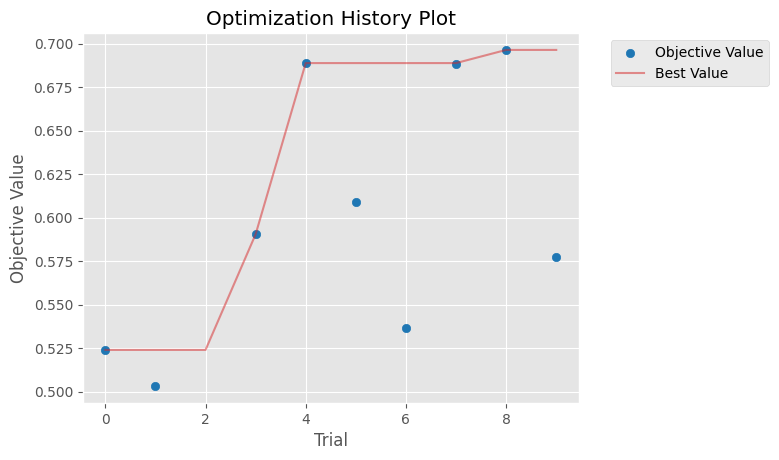

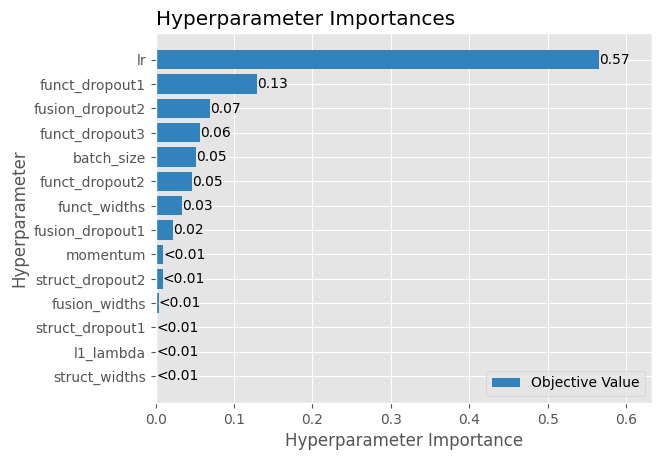

In [23]:
if do_optimization:
    import optuna.visualization.matplotlib as ovm

    # ---- EXERCISE ---- Bonus
    # TASK: plot the optimization history and the hyperparameter importances of the study    

    try:
        ovm.plot_optimization_history(study)
        plt.show()
        ovm.plot_param_importances(study)
        plt.show()
    
    except Exception as e:
        print('Visualization skipped (needs a few completed trials):', e)
    # ------------------

#### 4.3.4 Best parameters

Function `params_to_kwargs` converts the flat parameters (where widths are strings such as `'32_16_8'`) into the two dictionaries expected by the rest of the notebook: `best_model_kwargs` (architecture, used by `build_joint_model`) and `best_train_kwargs` (optimizer settings, passed to `train_one_fold`).

With `do_optimization = False` the parameters are read from the provided JSON file `best-params_joint-fusion_provided.json`; with `True`, they come from the study that has just run.

In [24]:
def params_to_kwargs(p):
    """Flat Optuna parameters (widths as 'a_b_c' strings) -> (model_kwargs, train_kwargs)."""

    s_h1, s_h2, s_out = (int(v) for v in p['struct_widths'].split('_'))
    f_h1, f_h2, f_h3, f_out = (int(v) for v in p['funct_widths'].split('_'))
    u_h1, u_h2 = (int(v) for v in p['fusion_widths'].split('_'))
    
    model_kwargs = dict(
        struct_h1=s_h1, struct_h2=s_h2, struct_out=s_out,
        struct_dropout1=p['struct_dropout1'], struct_dropout2=p['struct_dropout2'],
        funct_h1=f_h1, funct_h2=f_h2, funct_h3=f_h3, funct_out=f_out,
        funct_dropout1=p['funct_dropout1'], funct_dropout2=p['funct_dropout2'], funct_dropout3=p['funct_dropout3'],
        fusion_h1=u_h1, fusion_h2=u_h2,
        fusion_dropout1=p['fusion_dropout1'], fusion_dropout2=p['fusion_dropout2'],
    )
    
    train_kwargs = dict(lr=p['lr'], momentum=p['momentum'], batch_size=p['batch_size'], l1_lambda=p['l1_lambda'])
    
    return model_kwargs, train_kwargs


if do_optimization:
    best_params = study.best_params

else:
    with open(PARAMS_FILE, 'r') as f:
        best_params = json.load(f)

best_model_kwargs, best_train_kwargs = params_to_kwargs(best_params)

check_kwargs(best_model_kwargs, best_train_kwargs)

print('best_model_kwargs:', best_model_kwargs)
print('best_train_kwargs:', best_train_kwargs)


best_model_kwargs: {'struct_h1': 16, 'struct_h2': 8, 'struct_out': 4, 'struct_dropout1': 0.510059808712261, 'struct_dropout2': 0.29127760043465095, 'funct_h1': 32, 'funct_h2': 16, 'funct_h3': 8, 'funct_out': 4, 'funct_dropout1': 0.24190999753877407, 'funct_dropout2': 0.22034389671005078, 'funct_dropout3': 0.28536240252846234, 'fusion_h1': 16, 'fusion_h2': 8, 'fusion_dropout1': 0.39269940778391954, 'fusion_dropout2': 0.13934695530708924}
best_train_kwargs: {'lr': 0.0066939245292296735, 'momentum': 0.7088623380428449, 'batch_size': 32, 'l1_lambda': 0.0004255659322310981}


#### Energy monitoring
Now we can stop with the hyperparameter optimization task and start with the training phases monitoring.
We create a task for every version of the model (i.e., morphological, functional and joint)

In [25]:
# ENERGY MONITORING
if energy_monitoring:
    emissions_opt = tracker.stop_task()
    tracker.start_task("Training morphological model")

## 5. Cross-validation setting

The final evaluation runs on the 10 outer folds `OUTER` (Section 4.1). In every fold the models are trained at full budget (`EPOCHS` epochs, patience 5) using `best_model_kwargs` and `best_train_kwargs` from Section 4.3.

The three models of the notebook (structural-only, functional-only, joint) are evaluated on the same folds, so per-fold results are directly comparable.

In every fold we:

1. fit the scaler on the training subjects and reserve a stratified 15 % of them for early stopping, so the test fold plays no role in training;
2. train the model and plot its learning curves (training vs validation, i.e., the early-stopping subjects, accuracy and loss);
3. compute SHAP values for the test subjects;
4. compute the ROC curve and the AUC on the test subjects; the true positive rate is interpolated on a common grid of false positive rates (`interp_fpr`), so the curves of different folds can be averaged.

The two single-modality models in this section are *baselines*: they show how well each modality does alone, and give a reference for the importance of each feature, to be compared with the joint model of Section 6. They reuse, from the hyperparameters of the joint model, the keys that apply to their encoder together with the optimizer settings, so they do not need a search of their own.

### 5.0 A short primer on SHAP

On a neuroscientific perspective, it would be interesting to know *which features drive the predictions* of the model. **SHAP** (SHapley Additive exPlanations) answers this with Shapley values from cooperative game theory: each feature is a "player", and its SHAP value is its average marginal contribution to the prediction, taken over all the ways the other features could be present or absent.

Exact Shapley values are exponentially expensive, so we use approximations. In particular, we use `shap.GradientExplainer` (based on *expected gradients*, an extension of integrated gradients). It works with differentiable PyTorch models: it takes the model and a **background** set of samples (here the training fold) and estimates the SHAP values of the test samples from gradients of the output with respect to the inputs. For models with several inputs (e.g., the joint model) it accepts a list of tensors and returns one array of SHAP values per input.

How we use it:

* The model is put in `eval()` mode (no dropout, BatchNorm with running statistics).
* For each fold, SHAP values are computed on the held-out subjects, with the training fold as background. The code reshapes them to `(n_samples, n_features, 1)`.
* The *global importance* of a feature is the mean of |SHAP| over the subjects, which gives one number per feature and per fold. Stacking the folds gives a matrix `[n_features × n_folds]`, saved to CSV, which also shows how *stable* the importance is across folds.

Keep in mind that SHAP explains *the model*, not the underlying biology, and that correlated features (very common among functional connectivity values) share the credit among them.

### 5.1 Morphological model (structural features only)

This baseline reuses the structural encoder of the joint model and adds a single linear output unit (`SingleModalityModel`). `run_epoch_single` and `predict_proba_single` are the single-input equivalents of `run_epoch` and `predict_proba`.

In [26]:
class SingleModalityModel(nn.Module):
    """Single-branch classifier: reuses one of the joint-fusion encoders
    (MorphologicalModel / FunctionalModel) with a single linear output unit, so
    the same training / SHAP pipeline used for the joint model below can be
    run on each modality independently."""

    def __init__(self, encoder):
        super().__init__()
        self.encoder = encoder
        self.out = nn.Linear(encoder.out_dim, 1)
        self.out.apply(init_normal)

    def forward(self, x):
        return self.out(self.encoder(x))


def run_epoch_single(model, loader, criterion, optimizer=None, l1_lambda=0.01):
    train = optimizer is not None
    model.train(train)
    
    tot_loss = 0.0
    tot_correct = 0
    n = 0
    
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            logits = model(x).squeeze(-1)
            loss = criterion(logits, y)
        
            if train:
                optimizer.zero_grad()
                (loss + l1_penalty(model, l1_lambda)).backward()
                optimizer.step()
        
            bs = y.size(0)
            tot_loss += loss.item() * bs
            tot_correct += ((torch.sigmoid(logits) > 0.5).float() == y).sum().item()
            n += bs
    
    return tot_loss / n, tot_correct / n


@torch.no_grad()
def predict_proba_single(model, x):
    model.eval()
    logits = model(x.to(DEVICE)).squeeze(-1)
    return torch.sigmoid(logits).cpu().numpy()

The cross-validation loop below writes explicitly the same recipe as `train_one_fold` (weighted BCE, SGD with momentum, `ReduceLROnPlateau`, early stopping). The seeds are fixed once before the loop for reproducibility. The dictionaries `mk` and `tk` hold the tuned architecture and optimizer settings; `.get(key, default)` falls back to the original values when a key is missing.

For each fold the loop: 
1. splits the data and builds the tensors; 
2. builds the encoder and trains it; 
3. plots the learning curves; 
4. computes the SHAP values with the training fold as background; 
5. computes the ROC curve and AUC on the held-out fold and prints the fold result.

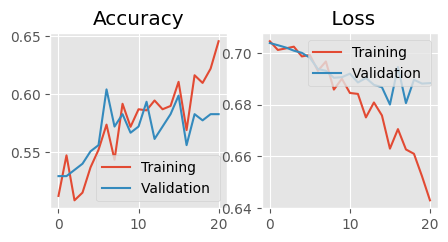

SHAP shape: structural (139, 221, 1)
fold  1  AUC 0.636  acc 0.604  (19.7s)


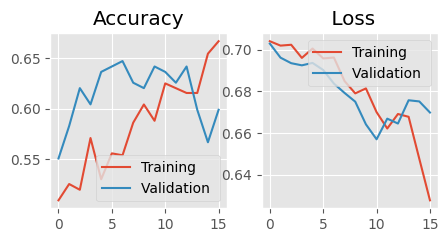

SHAP shape: structural (139, 221, 1)
fold  2  AUC 0.638  acc 0.604  (18.1s)


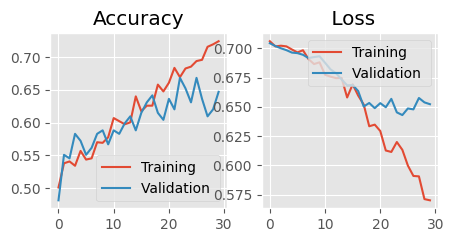

SHAP shape: structural (139, 221, 1)
fold  3  AUC 0.588  acc 0.568  (16.6s)


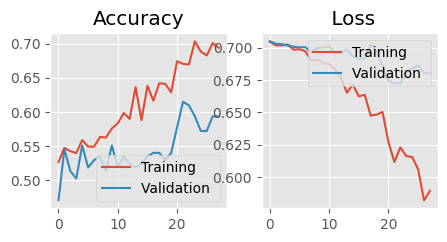

SHAP shape: structural (138, 221, 1)
fold  4  AUC 0.587  acc 0.558  (16.5s)


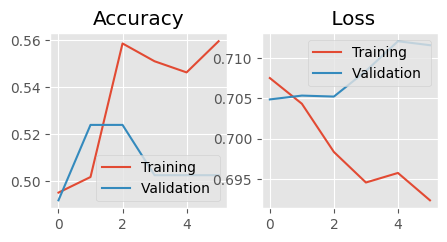

SHAP shape: structural (138, 221, 1)
fold  5  AUC 0.574  acc 0.594  (13.8s)


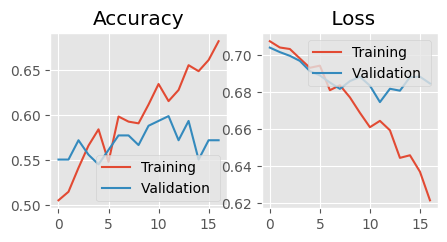

SHAP shape: structural (138, 221, 1)
fold  6  AUC 0.620  acc 0.572  (13.7s)


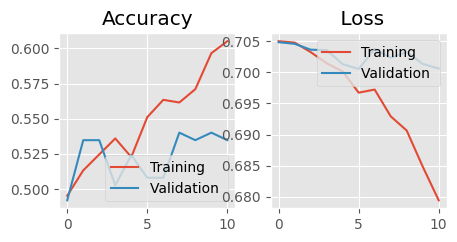

SHAP shape: structural (138, 221, 1)
fold  7  AUC 0.596  acc 0.580  (14.4s)


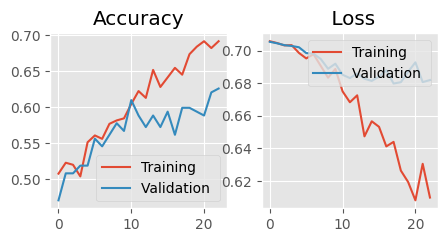

SHAP shape: structural (138, 221, 1)
fold  8  AUC 0.599  acc 0.580  (15.9s)


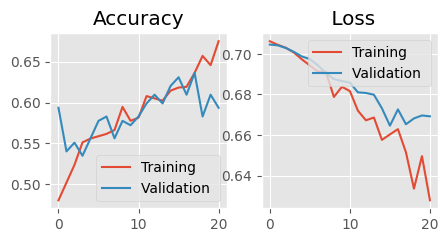

SHAP shape: structural (138, 221, 1)
fold  9  AUC 0.606  acc 0.558  (14.8s)


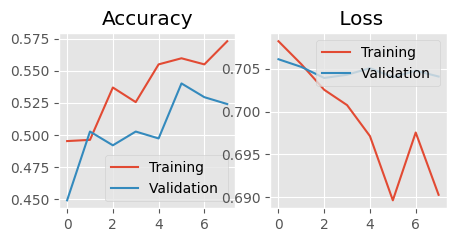

SHAP shape: structural (138, 221, 1)
fold 10  AUC 0.547  acc 0.587  (12.5s)


In [27]:
# for reproducibility
np.random.seed(1)          
torch.manual_seed(1)
torch.cuda.manual_seed_all(1)

interp_fpr = np.linspace(0, 1, 100)
mk = dict(best_model_kwargs or {})
tk = dict(best_train_kwargs or {})

acc_struct = []
AUC_struct = []
tprs_struct = []
shap_values_per_cv_struct = []

for fold, (train_index, test_index) in enumerate(OUTER):
    t0 = time.time()

    # --- subjects and tensors: scaler fitted on the training subjects only; 
    # a stratified 15 % of them is reserved for early stopping; 
    # the test fold is used only for the final metrics and SHAP ---
    
    fit_idx, es_idx = split_es(y_all, train_index, seed=OUTER_SEED + fold)
    
    # scaling operations here!
    sc = fit_scaler(X_all, train_index)
    
    Xfit_s, _, yfit = scaled_tensors(sc, fit_idx)
    Xes_s, _, yes = scaled_tensors(sc, es_idx)
    Xtr_s, _, _ = scaled_tensors(sc, train_index)    # whole training fold (SHAP background)
    Xte_s, _, yte = scaled_tensors(sc, test_index)
    y_test = yte.numpy()

    # --- fit a structural-only classifier (same encoder as the joint model,
    #     plus a single linear output unit) ---
    struct_encoder = MorphologicalModel(
        h1=mk.get('struct_h1', 32), h2=mk.get('struct_h2', 16),
        out=mk.get('struct_out', 8),
        dropout1=mk.get('struct_dropout1', 0.5),
        dropout2=mk.get('struct_dropout2', 0.2))
    
    model_struct = SingleModalityModel(struct_encoder).to(DEVICE)


    train_loader = DataLoader(TensorDataset(Xfit_s, yfit),
                              batch_size=tk.get('batch_size', BATCH_SIZE),
                              shuffle=True, drop_last=True)
    
    val_loader = DataLoader(TensorDataset(Xes_s, yes), batch_size=VAL_BATCH_SIZE, shuffle=False)

    n_pos, n_neg = yfit.sum(), yfit.numel() - yfit.sum()
    pos_weight = (n_neg / n_pos).to(DEVICE)
    
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    
    optimizer = SGD(model_struct.parameters(), lr=tk.get('lr', 0.001),
                    momentum=tk.get('momentum', 0.9))
    
    scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.1,
                                  patience=3, threshold=1e-4, min_lr=0)
    
    early_stop = EarlyStopping(patience=5, restore_best_weights=True)

    history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}
    
    for epoch in range(EPOCHS):
        tr_loss, tr_acc = run_epoch_single(model_struct, train_loader, criterion,
                                           optimizer, tk.get('l1_lambda', 0.01))
        val_loss, val_acc = run_epoch_single(model_struct, val_loader, criterion)
        history['loss'].append(tr_loss)
        history['accuracy'].append(tr_acc)
        history['val_loss'].append(val_loss)
        history['val_accuracy'].append(val_acc)
        scheduler.step(val_loss)
        if early_stop.step(val_loss, model_struct):
            break
    early_stop.restore(model_struct)

    # train and validation accuracy
    plt.figure(figsize=(5, 5))
    plt.subplot(2, 2, 1)
    plt.plot(history['accuracy'], label='Training ')
    plt.plot(history['val_accuracy'], label='Validation ')
    plt.legend(loc='lower right')
    plt.title('Accuracy')
    # train and validation loss
    plt.subplot(2, 2, 2)
    plt.plot(history['loss'], label='Training ')
    plt.plot(history['val_loss'], label='Validation ')
    plt.legend(loc='upper right')
    plt.title(' Loss')
    plt.show()

    # ---- SHAP ----
    model_struct.eval()
    explainer = shap.GradientExplainer(model_struct, Xtr_s.to(DEVICE))
    shap_values = explainer.shap_values(Xte_s.to(DEVICE))
    shap_s = np.asarray(shap_values[0] if isinstance(shap_values, list) else shap_values)
    if shap_s.ndim == 2:
        shap_s = shap_s[..., None]
    shap_values_per_cv_struct.append(shap_s)   # 221 features -> (n_test, 221, 1)
    print(f'SHAP shape: structural {shap_s.shape}')

    ###########################################################
    # Compute Receiver operating characteristic (ROC)
    preds = predict_proba_single(model_struct, Xte_s)
    acc_struct.append(float(((preds > 0.5) == y_test).mean()))
    fpr, tpr, _ = roc_curve(y_test, preds)
    roc_auc = auc(fpr, tpr)
    interp_tpr = np.interp(interp_fpr, fpr, tpr)
    tprs_struct.append(interp_tpr)
    AUC_struct.append(roc_auc)

    print(f'fold {fold+1:2d}  AUC {roc_auc:.3f}  acc {acc_struct[-1]:.3f}  ({time.time()-t0:.1f}s)')

#### Aggregating and saving

For each fold, the SHAP values are turned into one importance per feature (mean |SHAP| over the held-out subjects), giving a `[221 × n_folds]` matrix. The matrix and the per-fold metrics are saved to CSV, and the mean ± standard deviation of AUC and accuracy over the folds are printed. The suffix `_only` in the file name marks the standalone model, as opposed to the structural branch of the joint model.

In [28]:
# save SHAP values for morphological model (standalone structural-only classifier)
average_shap_values_struct = []
for i in range(len(AUC_struct)):
    df_per_obs = np.absolute(shap_values_per_cv_struct[i].copy())
    average_shap_values_struct.append(df_per_obs.mean(axis=0))

fold_struct = np.transpose(np.array(average_shap_values_struct)[..., 0])   # [221, n_folds]

# "_only" -> SHAP values of the standalone model, NOT the structural branch of
# the joint model (see the "Joint Fusion model" section below for that).
pd.DataFrame(fold_struct).to_csv(
    os.path.join(path_to_output_data, 'shap_value_morphological_only_10kf.csv'))

metrics_struct_df = pd.DataFrame({'fold': range(len(AUC_struct)), 'AUC': AUC_struct, 'accuracy': acc_struct})
metrics_struct_df.to_csv(os.path.join(path_to_output_data, 'standalone_torch_morphological_metrics_10kf.csv'), index=False)

print(f'AUC: {np.mean(AUC_struct)} (+- {np.std(AUC_struct)})')
print(f'accuracy: {np.mean(acc_struct)} (+- {np.std(acc_struct)})')
metrics_struct_df


AUC: 0.5991670611906734 (+- 0.026364260336847727)
accuracy: 0.5805963924512565 (+- 0.01610122443138933)


,fold,AUC,accuracy
0,0,0.636288,0.604317
1,1,0.637738,0.604317
2,2,0.588442,0.568345
3,3,0.586555,0.557971
4,4,0.573950,0.594203
5,5,0.620168,0.572464
6,6,0.595798,0.579710
7,7,0.598950,0.579710
8,8,0.606303,0.557971
9,9,0.547479,0.586957


In [29]:
# ENERGY MONITORING (optional, disabled)
if energy_monitoring:
    emissions_training_morph = tracker.stop_task()
    tracker.start_task("Training functional model")

### 5.2 Functional model (functional features only)

Same procedure as in 5.1, with the functional columns (`iloc[:, 222:]`) and the functional encoder. The SHAP matrix is now `[5253 × n_folds]`, so this loop is noticeably slower than the previous one. The next cell aggregates and saves the results as before.

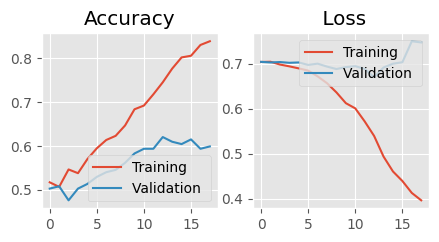

SHAP shape: functional (139, 5253, 1)
fold  1  AUC 0.678  acc 0.619  (15.8s)


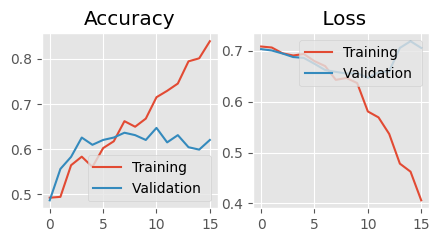

SHAP shape: functional (139, 5253, 1)
fold  2  AUC 0.690  acc 0.633  (16.7s)


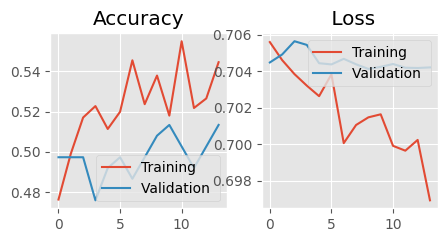

SHAP shape: functional (139, 5253, 1)
fold  3  AUC 0.482  acc 0.460  (14.8s)


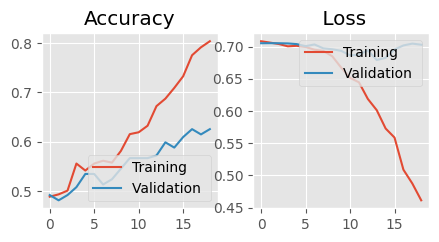

SHAP shape: functional (138, 5253, 1)
fold  4  AUC 0.603  acc 0.558  (16.2s)


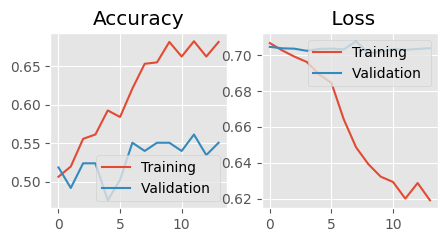

SHAP shape: functional (138, 5253, 1)
fold  5  AUC 0.606  acc 0.536  (14.7s)


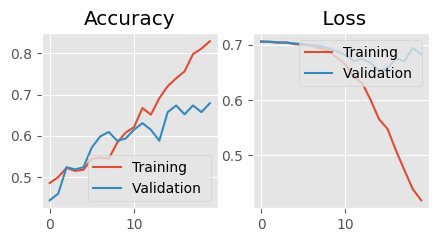

SHAP shape: functional (138, 5253, 1)
fold  6  AUC 0.617  acc 0.601  (14.8s)


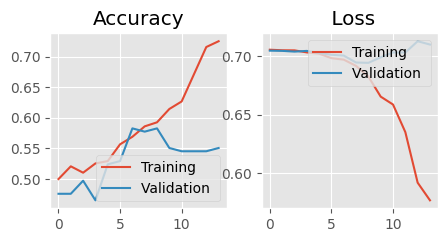

SHAP shape: functional (138, 5253, 1)
fold  7  AUC 0.602  acc 0.594  (14.8s)


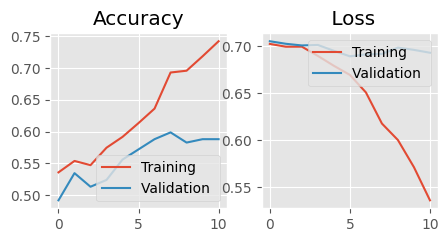

SHAP shape: functional (138, 5253, 1)
fold  8  AUC 0.599  acc 0.572  (15.9s)


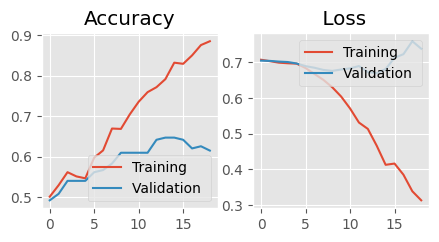

SHAP shape: functional (138, 5253, 1)
fold  9  AUC 0.617  acc 0.580  (15.5s)


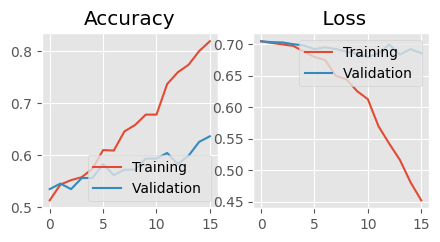

SHAP shape: functional (138, 5253, 1)
fold 10  AUC 0.627  acc 0.616  (16.3s)


In [30]:
acc_funct = []
AUC_funct = []
tprs_funct = []
shap_values_per_cv_funct = []

for fold, (train_index, test_index) in enumerate(OUTER):
    t0 = time.time()

    fit_idx, es_idx = split_es(y_all, train_index, seed=OUTER_SEED + fold)

    # scaling operations
    sc = fit_scaler(X_all, train_index)
    _, Xfit_f, yfit = scaled_tensors(sc, fit_idx)
    _, Xes_f, yes = scaled_tensors(sc, es_idx)
    _, Xtr_f, _ = scaled_tensors(sc, train_index)    # whole training fold (SHAP background)
    _, Xte_f, yte = scaled_tensors(sc, test_index)
    y_test = yte.numpy()

    # --- fit a functional-only classifier (same encoder as the joint model,
    #     plus a single linear output unit) ---
    funct_encoder = FunctionalModel(
        h1=mk.get('funct_h1', 64), h2=mk.get('funct_h2', 32),
        h3=mk.get('funct_h3', 16), out=mk.get('funct_out', 8),
        dropout1=mk.get('funct_dropout1', 0.5),
        dropout2=mk.get('funct_dropout2', 0.2),
        dropout3=mk.get('funct_dropout3', 0.2))
    model_funct = SingleModalityModel(funct_encoder).to(DEVICE)

    train_loader = DataLoader(TensorDataset(Xfit_f, yfit),
                              batch_size=tk.get('batch_size', BATCH_SIZE),
                              shuffle=True, drop_last=True)
    
    val_loader = DataLoader(TensorDataset(Xes_f, yes), batch_size=VAL_BATCH_SIZE, shuffle=False)

    n_pos, n_neg = yfit.sum(), yfit.numel() - yfit.sum()
    pos_weight = (n_neg / n_pos).to(DEVICE)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = SGD(model_funct.parameters(), lr=tk.get('lr', 0.001),
                    momentum=tk.get('momentum', 0.9))
    
    scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.1,
                                  patience=3, threshold=1e-4, min_lr=0)
    
    early_stop = EarlyStopping(patience=5, restore_best_weights=True)

    history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}
    for epoch in range(EPOCHS):
        tr_loss, tr_acc = run_epoch_single(model_funct, train_loader, criterion,
                                           optimizer, tk.get('l1_lambda', 0.01))
        val_loss, val_acc = run_epoch_single(model_funct, val_loader, criterion)
        history['loss'].append(tr_loss)
        history['accuracy'].append(tr_acc)
        history['val_loss'].append(val_loss)
        history['val_accuracy'].append(val_acc)
        scheduler.step(val_loss)
        if early_stop.step(val_loss, model_funct):
            break
    early_stop.restore(model_funct)

    # train and validation accuracy
    plt.figure(figsize=(5, 5))
    plt.subplot(2, 2, 1)
    plt.plot(history['accuracy'], label='Training ')
    plt.plot(history['val_accuracy'], label='Validation ')
    plt.legend(loc='lower right')
    plt.title('Accuracy')
    # train and validation loss
    plt.subplot(2, 2, 2)
    plt.plot(history['loss'], label='Training ')
    plt.plot(history['val_loss'], label='Validation ')
    plt.legend(loc='upper right')
    plt.title(' Loss')
    plt.show()

    # ---- SHAP ----
    model_funct.eval()
    explainer = shap.GradientExplainer(model_funct, Xtr_f.to(DEVICE))
    shap_values = explainer.shap_values(Xte_f.to(DEVICE))
    shap_f = np.asarray(shap_values[0] if isinstance(shap_values, list) else shap_values)
    if shap_f.ndim == 2:
        shap_f = shap_f[..., None]
    shap_values_per_cv_funct.append(shap_f)   # 5253 features -> (n_test, 5253, 1)
    print(f'SHAP shape: functional {shap_f.shape}')

    ###########################################################
    # Compute Receiver operating characteristic (ROC)
    preds = predict_proba_single(model_funct, Xte_f)
    acc_funct.append(float(((preds > 0.5) == y_test).mean()))
    fpr, tpr, _ = roc_curve(y_test, preds)
    roc_auc = auc(fpr, tpr)
    interp_tpr = np.interp(interp_fpr, fpr, tpr)
    tprs_funct.append(interp_tpr)
    AUC_funct.append(roc_auc)

    print(f'fold {fold+1:2d}  AUC {roc_auc:.3f}  acc {acc_funct[-1]:.3f}  ({time.time()-t0:.1f}s)')

In [31]:
# save SHAP values for functional model (standalone functional-only classifier)
average_shap_values_funct = []
for i in range(len(AUC_funct)):
    df_per_obs = np.absolute(shap_values_per_cv_funct[i].copy())
    average_shap_values_funct.append(df_per_obs.mean(axis=0))

fold_funct = np.transpose(np.array(average_shap_values_funct)[..., 0])   # [5253, n_folds]

# "_only" -> SHAP values of the standalone model, NOT the functional branch of
# the joint model (see the "Joint Fusion model" section below for that).
pd.DataFrame(fold_funct).to_csv(
    os.path.join(path_to_output_data, 'shap_value_functional_only_10kf.csv'))

metrics_funct_df = pd.DataFrame({'fold': range(len(AUC_funct)), 'AUC': AUC_funct, 'accuracy': acc_funct})
metrics_funct_df.to_csv(os.path.join(path_to_output_data, 'standalone_torch_functional_metrics_10kf.csv'), index=False)

print(f'AUC: {np.mean(AUC_funct)} (+- {np.std(AUC_funct)})')
print(f'accuracy: {np.mean(acc_funct)} (+- {np.std(acc_funct)})')
metrics_funct_df


AUC: 0.6121786601964729 (+- 0.052811673560758665)
accuracy: 0.5770201230320092 (+- 0.04789177479749932)


,fold,AUC,accuracy
0,0,0.677713,0.618705
1,1,0.689934,0.633094
2,2,0.482291,0.460432
3,3,0.603256,0.557971
4,4,0.606303,0.536232
5,5,0.617227,0.601449
6,6,0.601891,0.594203
7,7,0.598634,0.572464
8,8,0.617437,0.579710
9,9,0.627101,0.615942


In [32]:
# ENERGY MONITORING
if energy_monitoring:
    emissions_training_func = tracker.stop_task()
    tracker.start_task("Training joint model")

## 6. Joint Fusion model (your turn here!)

This is the main model: the two encoders and the fusion head of Section 3, trained end to end with `train_one_fold` and the tuned hyperparameters. The cross-validation loop follows the same steps as in Section 5, with one important difference in the SHAP part: the explainer takes **two** inputs, `GradientExplainer(model, [Xtr_s, Xtr_f])`, and returns two arrays, one with the SHAP values of the structural features and one with those of the functional features. These describe the importance of each feature *within the joint model*, which can differ from their importance in the standalone models.

The first cell below initializes the containers that collect the per-fold results and resets the seeds.

In [33]:
acc = []
AUC = []
shap_values_per_cv_s = []
shap_values_per_cv_f = []
var_f = []
var_s = []

# number of KFolds
n_cv = 10          
rs_ = 13

# for reproducibility
np.random.seed(1)          
torch.manual_seed(1)
torch.cuda.manual_seed_all(1)

tprs = []
aucs = []
interp_fpr = np.linspace(0, 1, 100)


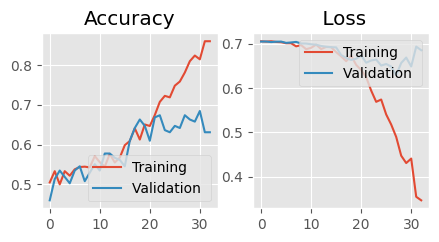

SHAP shapes: structural (139, 221, 1)  functional (139, 5253, 1)
fold  1  AUC 0.766  acc 0.683  (26.0s)


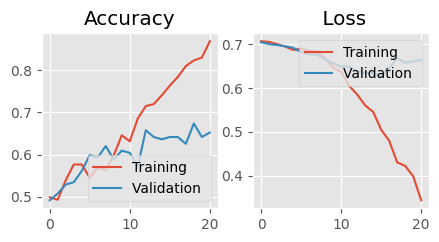

SHAP shapes: structural (139, 221, 1)  functional (139, 5253, 1)
fold  2  AUC 0.792  acc 0.734  (25.6s)


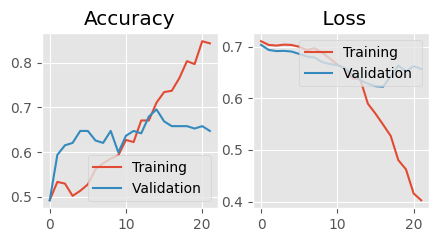

SHAP shapes: structural (139, 221, 1)  functional (139, 5253, 1)
fold  3  AUC 0.707  acc 0.662  (22.5s)


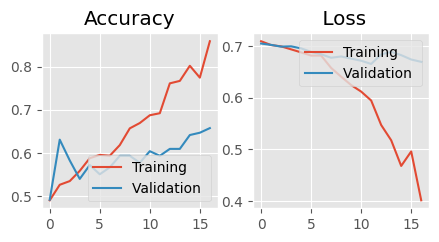

SHAP shapes: structural (138, 221, 1)  functional (138, 5253, 1)
fold  4  AUC 0.662  acc 0.645  (23.1s)


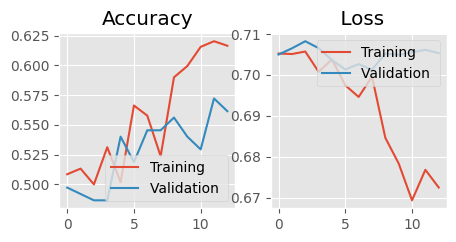

SHAP shapes: structural (138, 221, 1)  functional (138, 5253, 1)
fold  5  AUC 0.646  acc 0.601  (19.2s)


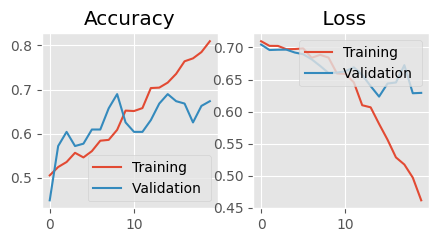

SHAP shapes: structural (138, 221, 1)  functional (138, 5253, 1)
fold  6  AUC 0.717  acc 0.710  (21.8s)


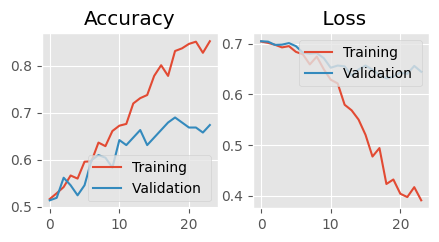

SHAP shapes: structural (138, 221, 1)  functional (138, 5253, 1)
fold  7  AUC 0.732  acc 0.674  (22.5s)


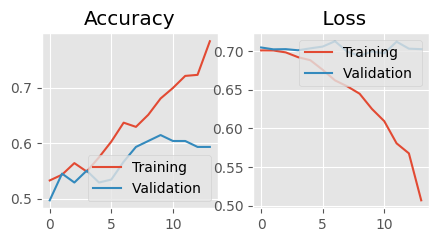

SHAP shapes: structural (138, 221, 1)  functional (138, 5253, 1)
fold  8  AUC 0.602  acc 0.623  (21.8s)


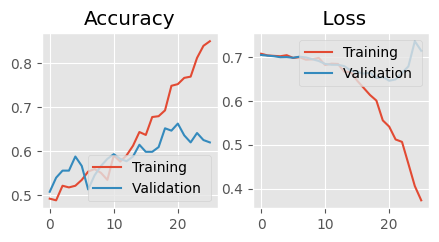

SHAP shapes: structural (138, 221, 1)  functional (138, 5253, 1)
fold  9  AUC 0.687  acc 0.623  (24.5s)


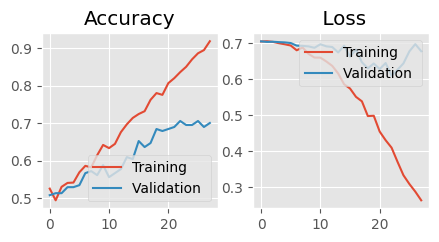

SHAP shapes: structural (138, 221, 1)  functional (138, 5253, 1)
fold 10  AUC 0.756  acc 0.652  (27.7s)


In [34]:
for fold, (train_index, test_index) in enumerate(OUTER):
    t0 = time.time()

    # --- subjects and tensors: scaler fitted on the training subjects only; a stratified 15 % of them is reserved
    #     for early stopping; the test fold is used only for the final metrics and SHAP ---
    fit_idx, es_idx = split_es(y_all, train_index, seed=OUTER_SEED + fold)
    
    # scaling operations
    sc = fit_scaler(X_all, train_index)
    Xfit_s, Xfit_f, yfit = scaled_tensors(sc, fit_idx)
    Xes_s, Xes_f, yes = scaled_tensors(sc, es_idx)
    Xtr_s, Xtr_f, _ = scaled_tensors(sc, train_index)    # whole training fold (SHAP background)
    Xte_s, Xte_f, yte = scaled_tensors(sc, test_index)
    y_test = yte.numpy()

    # ---- EXERCISE ---- Medium
    # TASK: train the joint model of this fold on the fit subjects, with early stopping on the es subjects, using the
    # tuned hyperparameters (best_model_kwargs, best_train_kwargs); then predict the probabilities of the test subjects
    # and store the test accuracy
    model_joint, history, _ = train_one_fold(
        Xfit_s, Xfit_f, yfit, Xes_s, Xes_f, yes, epochs=EPOCHS, patience=5,
        model_kwargs=best_model_kwargs, **best_train_kwargs)
    preds = predict_proba(model_joint, Xte_s, Xte_f)
    acc.append(float(((preds > 0.5) == y_test).mean()))
    # ------------------

    # Train and validation accuracy
    plt.figure(figsize=(5, 5))
    plt.subplot(2, 2, 1)
    plt.plot(history['accuracy'], label='Training ')
    plt.plot(history['val_accuracy'], label='Validation ')
    plt.legend(loc='lower right')
    plt.title('Accuracy')
    # Train and validation loss
    plt.subplot(2, 2, 2)
    plt.plot(history['loss'], label='Training ')
    plt.plot(history['val_loss'], label='Validation ')
    plt.legend(loc='upper right')
    plt.title(' Loss')
    plt.show()

    # ---- SHAP ----
    # GradientExplainer works with PyTorch too: it takes the nn.Module and a list of
    # background tensors. The model must be in eval() mode (no dropout / frozen BN).
    model_joint.eval()
    explainer = shap.GradientExplainer(model_joint, [Xtr_s.to(DEVICE), Xtr_f.to(DEVICE)])
    shap_values = explainer.shap_values([Xte_s.to(DEVICE), Xte_f.to(DEVICE)])

    # the downstream code expects arrays shaped (n_samples, n_features, 1)
    shap_s = np.asarray(shap_values[0])
    shap_f = np.asarray(shap_values[1])
    if shap_s.ndim == 2:
        shap_s = shap_s[..., None]
        shap_f = shap_f[..., None]

    # SHAP information per fold
    shap_values_per_cv_s.append(shap_s)   # 221 features   -> (138/139, 221, 1)
    shap_values_per_cv_f.append(shap_f)   # 5253 features  -> (138/139, 5253, 1)
    print(f'SHAP shapes: structural {shap_s.shape}  functional {shap_f.shape}')

    ###########################################################
    # Compute Receiver operating characteristic (ROC)
    fpr, tpr, _ = roc_curve(y_test, preds)
    roc_auc = auc(fpr, tpr)
    interp_tpr = np.interp(interp_fpr, fpr, tpr)
    tprs.append(interp_tpr)
    AUC.append(roc_auc)

    print(f'fold {fold+1:2d}  AUC {roc_auc:.3f}  acc {acc[-1]:.3f}  ({time.time()-t0:.1f}s)')

### 6.1 Mean ROC curve

Each fold gives one ROC curve, interpolated on the common `interp_fpr` grid. The plot shows the **mean curve** and a band of ±1 standard deviation across folds. The curve is forced to end at (1, 1) with `mean_tpr[-1] = 1.0`. The legend reports the AUC of the mean curve and the standard deviation of the per-fold AUCs (the two AUC values are slightly different quantities).

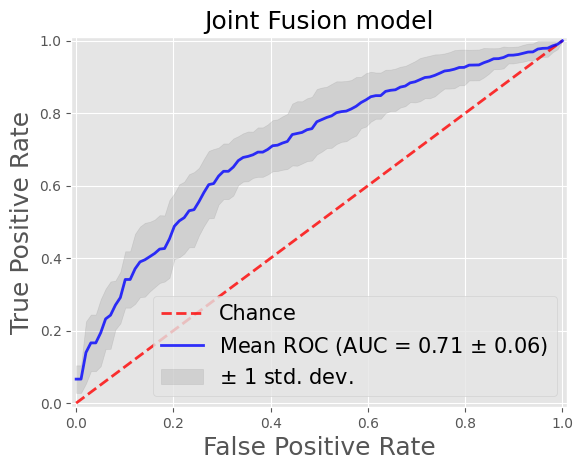

In [35]:
plt.figure()
plt.plot([0, 1], [0, 1], linestyle='--', lw=2, color='r',
      label='Chance', alpha=.8)

mean_tpr = np.mean(tprs, axis=0)
mean_tpr[-1] = 1.0
mean_auc = auc(interp_fpr, mean_tpr)
std_auc = np.std(AUC)
plt.plot(interp_fpr, mean_tpr, color='b',
        label=f'Mean ROC (AUC = {mean_auc:.2f} $\pm$ {std_auc:.2f})',
        lw=2, alpha=.8)

std_tpr = np.std(tprs, axis=0)
tprs_upper = np.minimum(mean_tpr + std_tpr, 1)
tprs_lower = np.maximum(mean_tpr - std_tpr, 0)
plt.fill_between(interp_fpr, tprs_lower, tprs_upper, color='grey', alpha=.2,
                label=r'$\pm$ 1 std. dev.')

plt.xlim([-0.01, 1.01])
plt.ylim([-0.01, 1.01])
plt.xlabel('False Positive Rate',fontsize=18)
plt.ylabel('True Positive Rate',fontsize=18)
plt.title('Joint Fusion model',fontsize=18)
plt.legend(loc="lower right", prop={'size': 15})
plt.show()

### 6.2 Summary metrics and saving

We print the mean ± standard deviation of AUC and accuracy over the 10 folds, and save the per-fold metrics and the ROC curves to CSV, so that they can be reloaded later and compared with other models.

In [36]:
# == Provide average scores ==
print(len(AUC))
print(f'AUC:{np.mean(AUC)} (+- {np.std(AUC)})')
print(f'accuracy: {np.mean(acc)} (+- {np.std(acc)})')

10
AUC:0.7067848266066991 (+- 0.05567676136187911)
accuracy: 0.660812219789386 (+- 0.03889755169944048)


In [37]:
# Persist per-fold metrics + ROC curves so they can be compared against Joint_Fusion_GAT.ipynb
metrics_df = pd.DataFrame({'fold': range(len(AUC)), 'AUC': AUC, 'accuracy': acc})
metrics_df.to_csv(os.path.join(path_to_output_data, 'joint_fusion_torch_metrics_10kf.csv'), index=False)

roc_df = pd.DataFrame({'fpr': interp_fpr})
for i, tpr in enumerate(tprs):
    roc_df[f'tpr_fold{i}'] = tpr
roc_df.to_csv(os.path.join(path_to_output_data, 'joint_fusion_torch_roc_10kf.csv'), index=False)

metrics_df


,fold,AUC,accuracy
0,0,0.766363,0.683453
1,1,0.792254,0.733813
2,2,0.706711,0.661871
3,3,0.662395,0.644928
4,4,0.646008,0.601449
5,5,0.716807,0.710145
6,6,0.732353,0.673913
7,7,0.602311,0.623188
8,8,0.686765,0.623188
9,9,0.755882,0.652174


### 6.3 Aggregating and saving the SHAP values

As in Section 5, the SHAP values of each fold are converted into mean |SHAP| per feature. We obtain `fold_s` (`[221 × n_folds]`) for the structural branch and `fold_f` (`[5253 × n_folds]`) for the functional branch of the joint model, which are saved to CSV.

In [38]:
# Establish lists to keep average Shap values
average_shap_values_s = []
average_shap_values_f = []

for i in range(0, len(AUC)):
    df_per_obs = shap_values_per_cv_s[i].copy()
    df_per_obs = np.absolute(df_per_obs)
    average_shap_values_s.append(df_per_obs.mean(axis=0))

    df_per_f = shap_values_per_cv_f[i].copy()
    df_per_f = np.absolute(df_per_f)
    average_shap_values_f.append(df_per_f.mean(axis=0))

fold_s = np.transpose(np.array(average_shap_values_s)[...,0])
fold_f = np.transpose(np.array(average_shap_values_f)[...,0])

In [39]:
# save SHAP values for joint model (structural / functional branches of the
# jointly-trained model -- NOT the standalone single-modality models above)
pd.DataFrame(fold_s).to_csv(
    os.path.join(path_to_output_data, 'shap_value_joint_nested_morphological_10kf.csv'))
pd.DataFrame(fold_f).to_csv(
    os.path.join(path_to_output_data, 'shap_value_joint_nested_functional_10kf.csv'))

print('fold_s', fold_s.shape, '| fold_f', fold_f.shape)


fold_s (221, 10) | fold_f (5253, 10)


### 6.4 Comparing the three models

The last plot overlays the mean ROC curves (with ±1 std bands) of the joint model, the functional-only model and the morphological-only model. It uses the results of Sections 5.1 and 5.2 (`tprs_struct`, `tprs_funct`, `AUC_struct`, `AUC_funct`), so those sections must have been run beforehand. The legend is placed outside the axes.

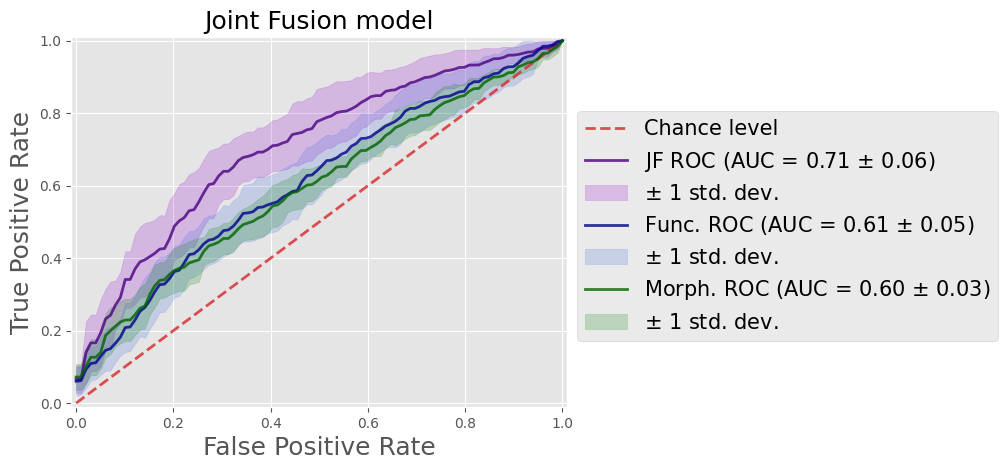

In [40]:
plt.figure()
plt.plot([0, 1], [0, 1], linestyle='--', lw=2, color='tab:red',
      label='Chance level', alpha=.8)

mean_tpr = np.mean(tprs, axis=0)
mean_tpr[-1] = 1.0
mean_auc = auc(interp_fpr, mean_tpr)
std_auc = np.std(AUC)
plt.plot(interp_fpr, mean_tpr, color='indigo',
        label=f'JF ROC (AUC = {mean_auc:.2f} $\pm$ {std_auc:.2f})',
        lw=2, alpha=.8)

std_tpr = np.std(tprs, axis=0)
tprs_upper = np.minimum(mean_tpr + std_tpr, 1)
tprs_lower = np.maximum(mean_tpr - std_tpr, 0)
plt.fill_between(interp_fpr, tprs_lower, tprs_upper, color='darkviolet', alpha=.2,
                label=r'$\pm$ 1 std. dev.')

mean_tpr_func = np.mean(tprs_funct, axis=0)
mean_tpr_func[-1] = 1.0
mean_auc_func = auc(interp_fpr, mean_tpr_func)
std_auc_func = np.std(AUC_funct)
plt.plot(interp_fpr, mean_tpr_func, color='darkblue',
        label=f'Func. ROC (AUC = {mean_auc_func:.2f} $\pm$ {std_auc_func:.2f})',
        lw=2, alpha=.8)

std_tpr_func = np.std(tprs_funct, axis=0)
tprs_upper_func = np.minimum(mean_tpr_func + std_tpr_func, 1)
tprs_lower_func = np.maximum(mean_tpr_func - std_tpr_func, 0)
plt.fill_between(interp_fpr, tprs_lower_func, tprs_upper_func, color='royalblue', alpha=.2,
                label=r'$\pm$ 1 std. dev.')

mean_tpr_morph = np.mean(tprs_struct, axis=0)
mean_tpr_morph[-1] = 1.0
mean_auc_morph = auc(interp_fpr, mean_tpr_morph)
std_auc_morph = np.std(AUC_struct)
plt.plot(interp_fpr, mean_tpr_morph, color='darkgreen',
        label=f'Morph. ROC (AUC = {mean_auc_morph:.2f} $\pm$ {std_auc_morph:.2f})',
        lw=2, alpha=.8)

std_tpr_morph = np.std(tprs_struct, axis=0)
tprs_upper_morph = np.minimum(mean_tpr_morph + std_tpr_morph, 1)
tprs_lower_morph = np.maximum(mean_tpr_morph - std_tpr_morph, 0)
plt.fill_between(interp_fpr, tprs_lower_morph, tprs_upper_morph, color='green', alpha=.2,
                label=r'$\pm$ 1 std. dev.')

plt.xlim([-0.01, 1.01])
plt.ylim([-0.01, 1.01])
plt.xlabel('False Positive Rate',fontsize=18)
plt.ylabel('True Positive Rate',fontsize=18)
plt.title('Joint Fusion model',fontsize=18)
plt.legend(loc="lower right", prop={'size': 15}, bbox_to_anchor=(1.89, 0.15))
plt.show()

In [41]:
# ENERGY MONITORING
if energy_monitoring:
    emissions_training_joint = tracker.stop_task()
    emissions = tracker.stop()